In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('/content/sonar.csv')
df.head()

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
0,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
1,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
2,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
3,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R
4,0.0286,0.0453,0.0277,0.0174,0.0384,0.0990,0.1201,0.1833,0.2105,0.3039,...,0.0045,0.0014,0.0038,0.0013,0.0089,0.0057,0.0027,0.0051,0.0062,R


In [3]:
df.tail()

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
202,0.0187,0.0346,0.0168,0.0177,0.0393,0.1630,0.2028,0.1694,0.2328,0.2684,...,0.0116,0.0098,0.0199,0.0033,0.0101,0.0065,0.0115,0.0193,0.0157,M
203,0.0323,0.0101,0.0298,0.0564,0.0760,0.0958,0.0990,0.1018,0.1030,0.2154,...,0.0061,0.0093,0.0135,0.0063,0.0063,0.0034,0.0032,0.0062,0.0067,M
204,0.0522,0.0437,0.0180,0.0292,0.0351,0.1171,0.1257,0.1178,0.1258,0.2529,...,0.0160,0.0029,0.0051,0.0062,0.0089,0.0140,0.0138,0.0077,0.0031,M
205,0.0303,0.0353,0.0490,0.0608,0.0167,0.1354,0.1465,0.1123,0.1945,0.2354,...,0.0086,0.0046,0.0126,0.0036,0.0035,0.0034,0.0079,0.0036,0.0048,M
206,0.0260,0.0363,0.0136,0.0272,0.0214,0.0338,0.0655,0.1400,0.1843,0.2354,...,0.0146,0.0129,0.0047,0.0039,0.0061,0.0040,0.0036,0.0061,0.0115,M


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0.0200  207 non-null    float64
 1   0.0371  207 non-null    float64
 2   0.0428  207 non-null    float64
 3   0.0207  207 non-null    float64
 4   0.0954  207 non-null    float64
 5   0.0986  207 non-null    float64
 6   0.1539  207 non-null    float64
 7   0.1601  207 non-null    float64
 8   0.3109  207 non-null    float64
 9   0.2111  207 non-null    float64
 10  0.1609  207 non-null    float64
 11  0.1582  207 non-null    float64
 12  0.2238  207 non-null    float64
 13  0.0645  207 non-null    float64
 14  0.0660  207 non-null    float64
 15  0.2273  207 non-null    float64
 16  0.3100  207 non-null    float64
 17  0.2999  207 non-null    float64
 18  0.5078  207 non-null    float64
 19  0.4797  207 non-null    float64
 20  0.5783  207 non-null    float64
 21  0.5071  207 non-null    float64
 22  0.

In [5]:
df.shape

(207, 61)

In [6]:
df.columns

Index(['0.0200', '0.0371', '0.0428', '0.0207', '0.0954', '0.0986', '0.1539',
       '0.1601', '0.3109', '0.2111', '0.1609', '0.1582', '0.2238', '0.0645',
       '0.0660', '0.2273', '0.3100', '0.2999', '0.5078', '0.4797', '0.5783',
       '0.5071', '0.4328', '0.5550', '0.6711', '0.6415', '0.7104', '0.8080',
       '0.6791', '0.3857', '0.1307', '0.2604', '0.5121', '0.7547', '0.8537',
       '0.8507', '0.6692', '0.6097', '0.4943', '0.2744', '0.0510', '0.2834',
       '0.2825', '0.4256', '0.2641', '0.1386', '0.1051', '0.1343', '0.0383',
       '0.0324', '0.0232', '0.0027', '0.0065', '0.0159', '0.0072', '0.0167',
       '0.0180', '0.0084', '0.0090', '0.0032', 'R'],
      dtype='object')

In [7]:
df.isnull().sum()

,0
0.0200,0
0.0371,0
0.0428,0
0.0207,0
0.0954,0
...,...
0.0180,0
0.0084,0
0.0090,0
0.0032,0


In [8]:
df['R'].nunique()

2

In [9]:
df['R'].unique()

array(['R', 'M'], dtype=object)

In [10]:
df['0.0200'].nunique()

176

In [11]:
df['0.0200'].unique()

array([0.0453, 0.0262, 0.01  , 0.0762, 0.0286, 0.0317, 0.0519, 0.0223,
       0.0164, 0.0039, 0.0123, 0.0079, 0.009 , 0.0124, 0.0298, 0.0352,
       0.0192, 0.027 , 0.0126, 0.0473, 0.0664, 0.0099, 0.0115, 0.0293,
       0.0201, 0.0151, 0.0177, 0.0189, 0.024 , 0.0084, 0.0195, 0.0442,
       0.0311, 0.0206, 0.0094, 0.0333, 0.0091, 0.0068, 0.0093, 0.0211,
       0.0257, 0.0408, 0.0308, 0.0373, 0.019 , 0.0119, 0.0353, 0.0131,
       0.0087, 0.0132, 0.0152, 0.0216, 0.0225, 0.0125, 0.013 , 0.0135,
       0.0086, 0.0067, 0.0071, 0.0176, 0.0265, 0.0368, 0.0065, 0.0036,
       0.0208, 0.0139, 0.0109, 0.0202, 0.0239, 0.0336, 0.0231, 0.0108,
       0.0229, 0.0409, 0.0217, 0.0378, 0.0365, 0.0188, 0.0856, 0.0274,
       0.0235, 0.0253, 0.026 , 0.0459, 0.0025, 0.0291, 0.0181, 0.0491,
       0.1313, 0.0629, 0.0335, 0.0587, 0.0162, 0.0307, 0.0116, 0.0331,
       0.0428, 0.0599, 0.0264, 0.021 , 0.053 , 0.0454, 0.0283, 0.0114,
       0.0414, 0.0228, 0.0363, 0.0261, 0.0346, 0.0249, 0.0388, 0.0715,
      

In [12]:
df['0.0371'].nunique()

181

In [13]:
df['0.0371'].unique()

array([0.0523, 0.0582, 0.0171, 0.0666, 0.0453, 0.0956, 0.0548, 0.0375,
       0.0173, 0.0063, 0.0309, 0.0086, 0.0062, 0.0433, 0.0615, 0.0116,
       0.0607, 0.0092, 0.0149, 0.0509, 0.0575, 0.0484, 0.015 , 0.0644,
       0.0026, 0.032 , 0.03  , 0.0275, 0.0308, 0.0218, 0.0153, 0.0213,
       0.0477, 0.0491, 0.0132, 0.0166, 0.0221, 0.0022, 0.0232, 0.0185,
       0.0319, 0.0269, 0.0447, 0.0653, 0.0339, 0.0281, 0.0038, 0.0713,
       0.0068, 0.0046, 0.0378, 0.008 , 0.0102, 0.0124, 0.0019, 0.0152,
       0.0006, 0.0045, 0.0215, 0.0096, 0.0103, 0.0172, 0.044 , 0.0403,
       0.0142, 0.0122, 0.0078, 0.0186, 0.0222, 0.0093, 0.0104, 0.0189,
       0.0294, 0.0351, 0.0369, 0.0194, 0.0421, 0.034 , 0.0318, 0.1632,
       0.037 , 0.0454, 0.0242, 0.0291, 0.0519, 0.0808, 0.0192, 0.0437,
       0.04  , 0.0146, 0.0279, 0.2339, 0.0423, 0.1065, 0.0134, 0.121 ,
       0.0253, 0.0179, 0.0555, 0.0474, 0.0071, 0.0121, 0.0885, 0.0472,
       0.0599, 0.0436, 0.0333, 0.0106, 0.0478, 0.0266, 0.0041, 0.0119,
      

In [14]:
df['0.0428'].nunique()

189

In [15]:
df['0.0428'].unique()

array([0.0843, 0.1099, 0.0623, 0.0481, 0.0277, 0.1321, 0.0842, 0.0484,
       0.0347, 0.0152, 0.0169, 0.0055, 0.0253, 0.0604, 0.065 , 0.0191,
       0.0378, 0.0145, 0.0641, 0.0819, 0.0299, 0.0136, 0.039 , 0.0138,
       0.0599, 0.0288, 0.019 , 0.0197, 0.0324, 0.0291, 0.0058, 0.0049,
       0.0692, 0.0533, 0.0398, 0.027 , 0.0196, 0.0206, 0.0513, 0.0056,
       0.0415, 0.0217, 0.0388, 0.0397, 0.0202, 0.0232, 0.0642, 0.0326,
       0.0308, 0.0081, 0.0257, 0.0188, 0.0123, 0.0113, 0.0174, 0.0075,
       0.0218, 0.0088, 0.0051, 0.0242, 0.0024, 0.0135, 0.0501, 0.0137,
       0.0317, 0.0181, 0.0273, 0.0068, 0.0092, 0.0131, 0.0089, 0.0121,
       0.0325, 0.0466, 0.0476, 0.003 , 0.004 , 0.0155, 0.0573, 0.0392,
       0.0423, 0.1636, 0.0953, 0.0382, 0.0621, 0.0749, 0.0507, 0.0254,
       0.0171, 0.0771, 0.0026, 0.0592, 0.3059, 0.0554, 0.1526, 0.0696,
       0.1268, 0.0262, 0.0653, 0.0449, 0.0474, 0.0708, 0.0498, 0.0342,
       0.0203, 0.1997, 0.0697, 0.0656, 0.0269, 0.0447, 0.0306, 0.013 ,
      

In [16]:
df['0.0207'].nunique()

180

In [17]:
df['0.0207'].unique()

array([0.0689, 0.1083, 0.0205, 0.0394, 0.0174, 0.1408, 0.0319, 0.0475,
       0.007 , 0.0336, 0.0313, 0.025 , 0.0489, 0.0449, 0.0921, 0.0469,
       0.0774, 0.0278, 0.1732, 0.1252, 0.0372, 0.0297, 0.0076, 0.0173,
       0.0062, 0.105 , 0.0371, 0.0622, 0.0569, 0.0432, 0.019 , 0.0581,
       0.0831, 0.0359, 0.0481, 0.0206, 0.0505, 0.0444, 0.0064, 0.0286,
       0.0339, 0.0239, 0.0604, 0.0889, 0.0225, 0.0452, 0.06  , 0.0272,
       0.0311, 0.023 , 0.0141, 0.0245, 0.0263, 0.0152, 0.0097, 0.0175,
       0.0456, 0.0289, 0.0445, 0.0058, 0.0494, 0.0285, 0.0084, 0.0293,
       0.0406, 0.0139, 0.0108, 0.0387, 0.0211, 0.0378, 0.044 , 0.0539,
       0.0304, 0.046 , 0.0375, 0.013 , 0.0236, 0.035 , 0.1421, 0.0824,
       0.0203, 0.056 , 0.0519, 0.0518, 0.0244, 0.0061, 0.0228, 0.0809,
       0.127 , 0.4264, 0.0783, 0.1229, 0.118 , 0.1498, 0.0386, 0.0521,
       0.1096, 0.0818, 0.0618, 0.0793, 0.1036, 0.2604, 0.1021, 0.0229,
       0.0384, 0.0844, 0.0376, 0.0842, 0.021 , 0.0749, 0.0243, 0.0441,
      

In [18]:
df['0.0954'].nunique()

192

In [19]:
df['0.0954'].unique()

array([0.1183, 0.0974, 0.0205, 0.059 , 0.0384, 0.1674, 0.1158, 0.0647,
       0.0187, 0.031 , 0.0358, 0.0344, 0.1197, 0.0597, 0.1615, 0.0737,
       0.1388, 0.0412, 0.2565, 0.1783, 0.0458, 0.0652, 0.0211, 0.0476,
       0.0133, 0.1163, 0.063 , 0.0416, 0.008 , 0.033 , 0.0951, 0.0319,
       0.0278, 0.0079, 0.0681, 0.0679, 0.018 , 0.0657, 0.0249, 0.026 ,
       0.0121, 0.0305, 0.1315, 0.0496, 0.157 , 0.0179, 0.0333, 0.1397,
       0.037 , 0.0085, 0.0586, 0.013 , 0.0436, 0.0547, 0.0097, 0.0608,
       0.0445, 0.0362, 0.0525, 0.0561, 0.0667, 0.0197, 0.0253, 0.0262,
       0.082 , 0.0391, 0.0357, 0.0217, 0.053 , 0.061 , 0.0215, 0.0807,
       0.0794, 0.0339, 0.0752, 0.0455, 0.0839, 0.0183, 0.1081, 0.1787,
       0.113 , 0.0385, 0.1129, 0.0227, 0.1072, 0.1724, 0.0352, 0.0067,
       0.0434, 0.0521, 0.0421, 0.1772, 0.401 , 0.062 , 0.1437, 0.0348,
       0.1436, 0.0645, 0.0611, 0.1913, 0.0835, 0.1215, 0.1026, 0.1043,
       0.1675, 0.3225, 0.1217, 0.0419, 0.1296, 0.1117, 0.1409, 0.1364,
      

In [20]:
df.isnull().sum()

,0
0.0200,0
0.0371,0
0.0428,0
0.0207,0
0.0954,0
...,...
0.0180,0
0.0084,0
0.0090,0
0.0032,0


#No Null value Found

In [21]:
df.head()

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
0,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
1,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
2,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
3,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R
4,0.0286,0.0453,0.0277,0.0174,0.0384,0.0990,0.1201,0.1833,0.2105,0.3039,...,0.0045,0.0014,0.0038,0.0013,0.0089,0.0057,0.0027,0.0051,0.0062,R


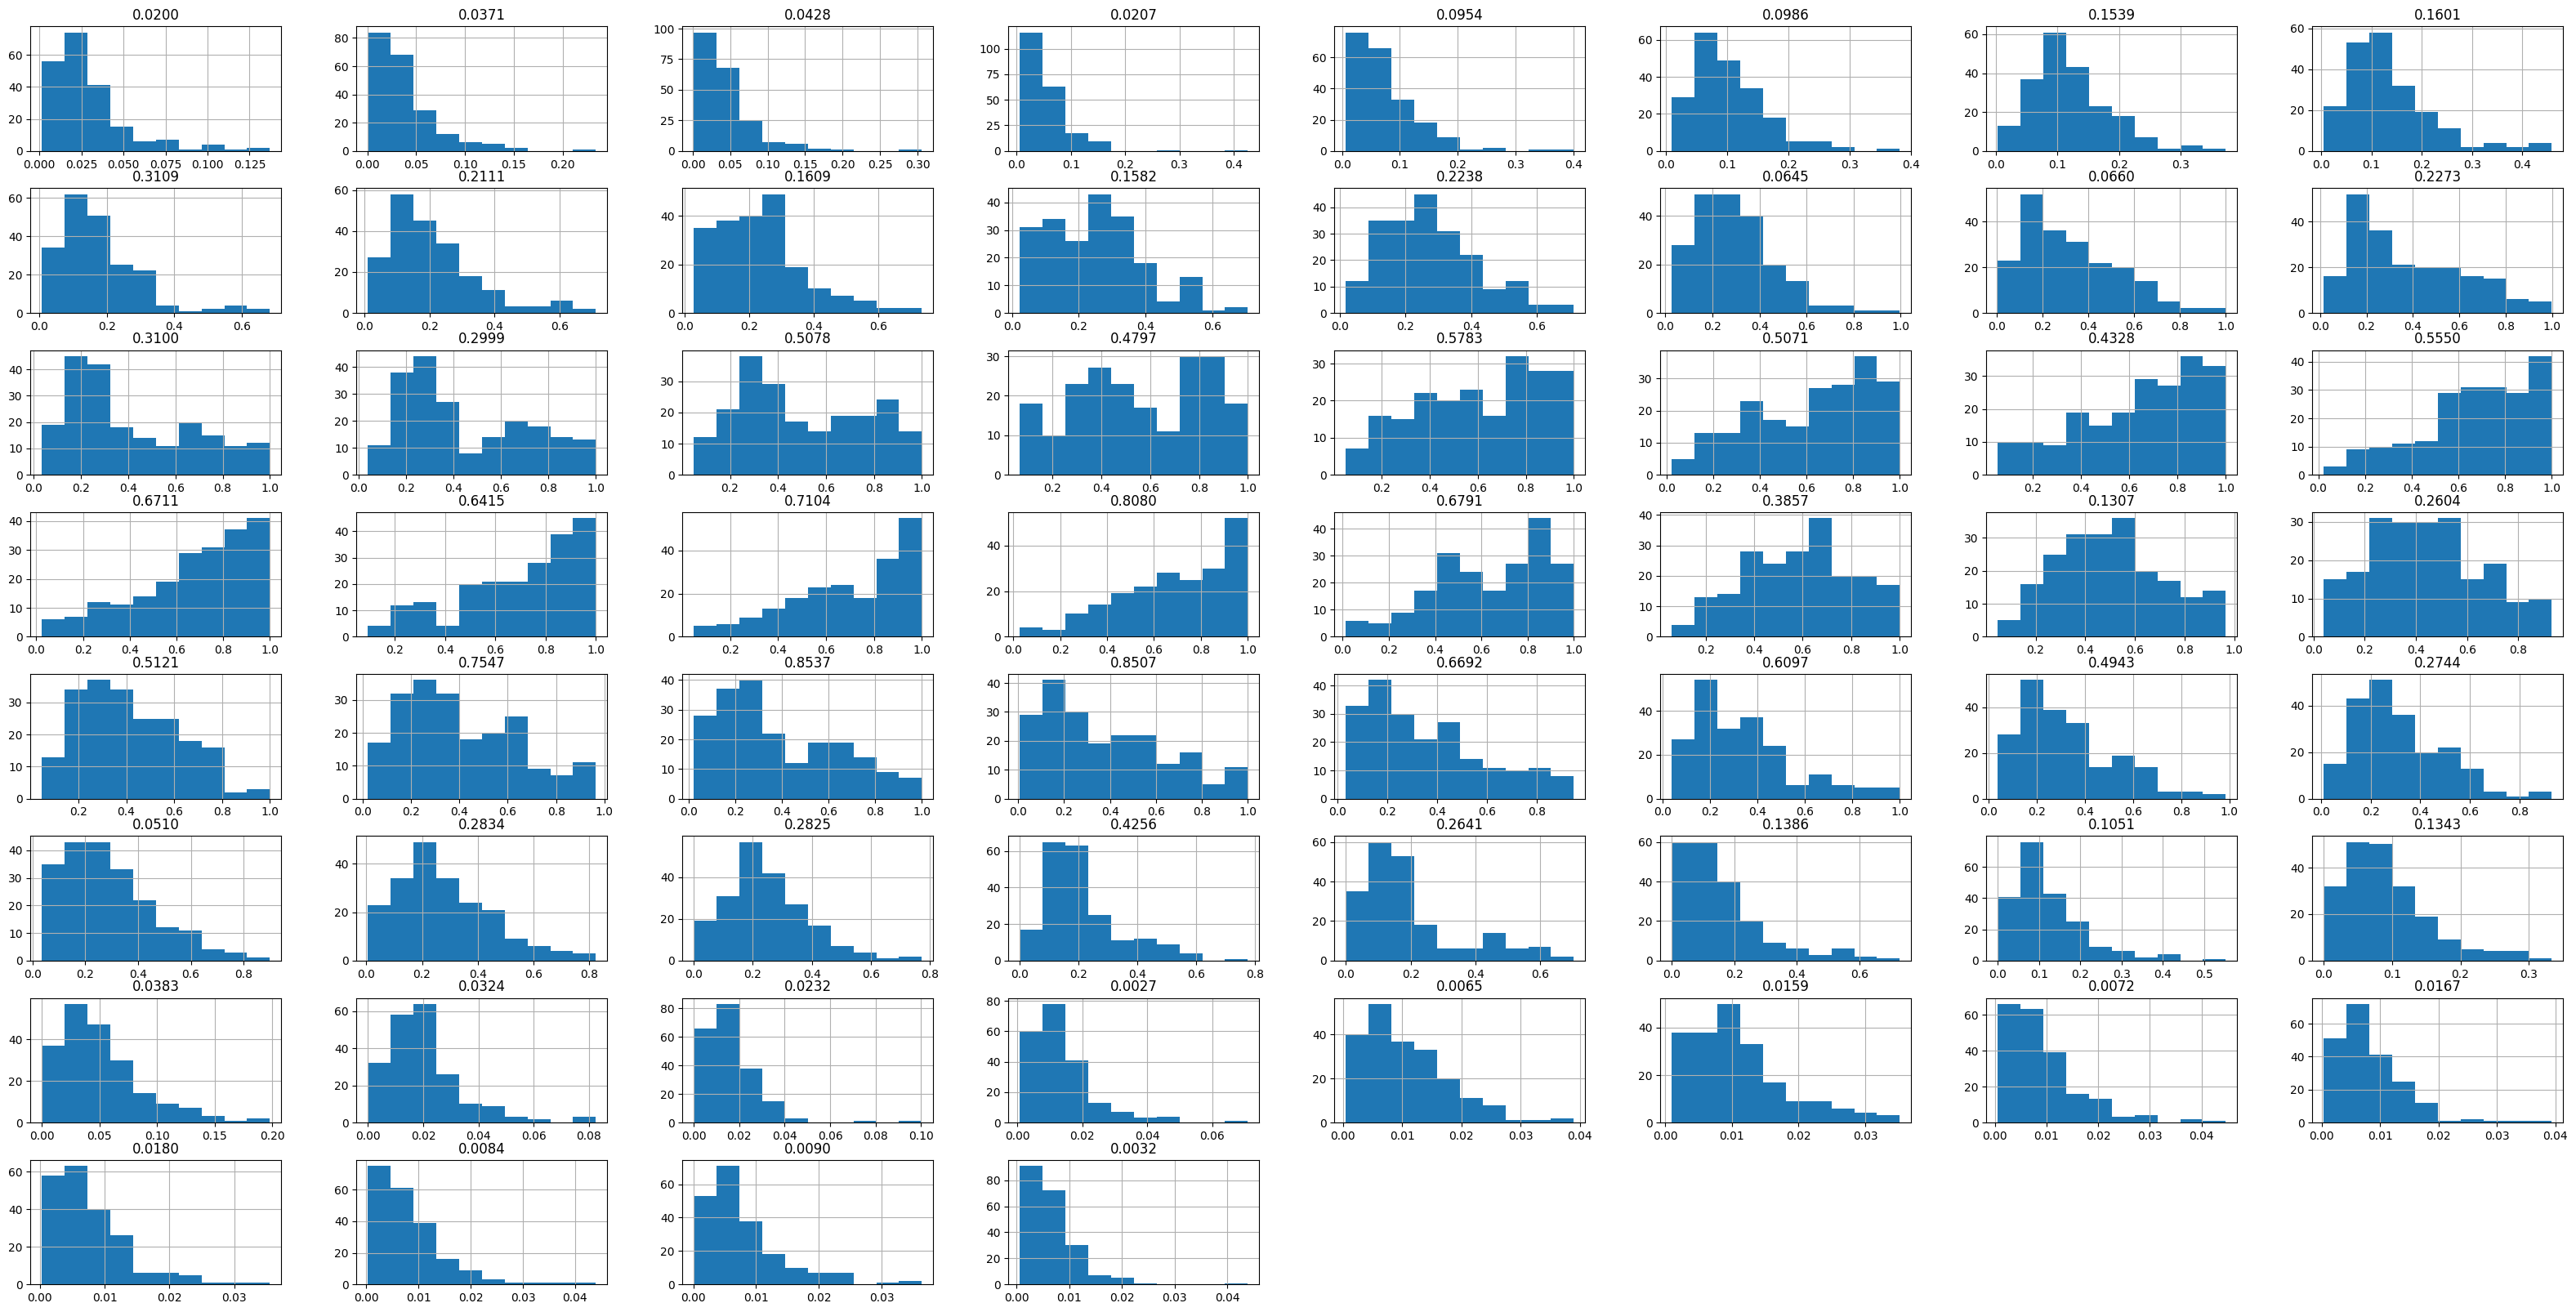

In [24]:
df.hist(figsize=(40,20))
plt.show()

In [25]:
df.sample(3)

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
199,0.0131,0.0387,0.0329,0.0078,0.0721,0.1341,0.1626,0.1902,0.2610,0.3193,...,0.0150,0.0076,0.0032,0.0037,0.0071,0.0040,0.0009,0.0015,0.0085,M
188,0.0158,0.0239,0.0150,0.0494,0.0988,0.1425,0.1463,0.1219,0.1697,0.1923,...,0.0121,0.0108,0.0057,0.0028,0.0079,0.0034,0.0046,0.0022,0.0021,M
121,0.0249,0.0119,0.0277,0.0760,0.1218,0.1538,0.1192,0.1229,0.2119,0.2531,...,0.0027,0.0068,0.0150,0.0012,0.0133,0.0048,0.0244,0.0077,0.0074,M


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0.0200  207 non-null    float64
 1   0.0371  207 non-null    float64
 2   0.0428  207 non-null    float64
 3   0.0207  207 non-null    float64
 4   0.0954  207 non-null    float64
 5   0.0986  207 non-null    float64
 6   0.1539  207 non-null    float64
 7   0.1601  207 non-null    float64
 8   0.3109  207 non-null    float64
 9   0.2111  207 non-null    float64
 10  0.1609  207 non-null    float64
 11  0.1582  207 non-null    float64
 12  0.2238  207 non-null    float64
 13  0.0645  207 non-null    float64
 14  0.0660  207 non-null    float64
 15  0.2273  207 non-null    float64
 16  0.3100  207 non-null    float64
 17  0.2999  207 non-null    float64
 18  0.5078  207 non-null    float64
 19  0.4797  207 non-null    float64
 20  0.5783  207 non-null    float64
 21  0.5071  207 non-null    float64
 22  0.

In [27]:
df.describe()

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0232,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032
count,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,...,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean,0.029208,0.038443,0.043837,0.054053,0.075105,0.104599,0.121591,0.134677,0.177361,0.208245,...,0.016034,0.013472,0.010729,0.010917,0.009300,0.008181,0.007771,0.007947,0.007936,0.006523
std,0.023038,0.033040,0.038521,0.046583,0.055669,0.059247,0.061897,0.085340,0.118311,0.134741,...,0.012027,0.009628,0.007071,0.007310,0.007103,0.005719,0.005756,0.006485,0.006196,0.005038
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013300,0.016400,0.018900,0.024450,0.037700,0.066950,0.080600,0.080350,0.096750,0.111150,...,0.008350,0.007350,0.005050,0.005350,0.004100,0.004400,0.003700,0.003600,0.003650,0.003100
50%,0.022800,0.030800,0.034200,0.044100,0.062000,0.092100,0.105600,0.111900,0.152200,0.181000,...,0.013800,0.011500,0.009600,0.009300,0.007500,0.006800,0.005900,0.005800,0.006300,0.005300
75%,0.035800,0.048100,0.058200,0.065700,0.101050,0.134150,0.153050,0.169800,0.231500,0.269000,...,0.020700,0.016750,0.014900,0.014450,0.012100,0.010350,0.010350,0.010400,0.010350,0.008550
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [53]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.head()

,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
0,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
1,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
2,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
3,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R
4,0.0286,0.0453,0.0277,0.0174,0.0384,0.0990,0.1201,0.1833,0.2105,0.3039,...,0.0045,0.0014,0.0038,0.0013,0.0089,0.0057,0.0027,0.0051,0.0062,R


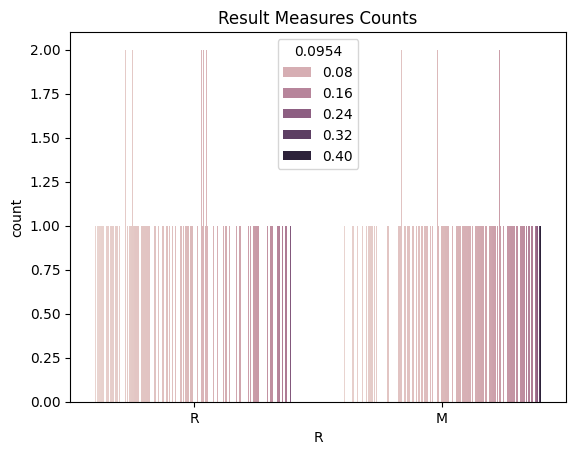

In [29]:
sns.countplot(x='R' , hue='0.0954',data=df)
plt.title('Result Measures Counts')
plt.show()

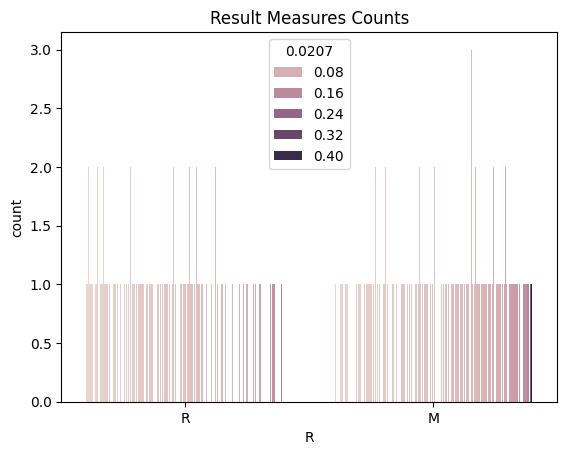

In [34]:
sns.countplot(x='R' , hue='0.0207',data=df)
plt.title('Result Measures Counts')
plt.show()

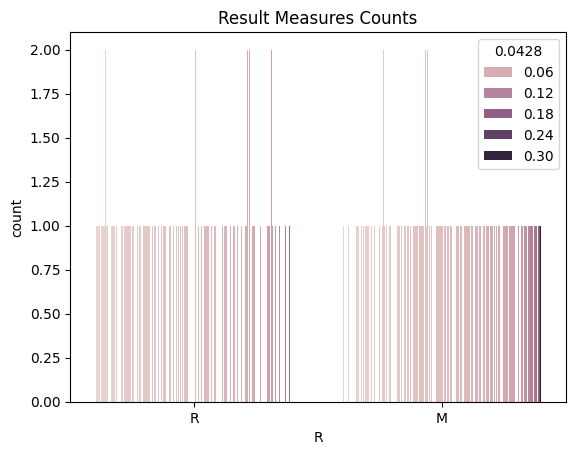

In [33]:
sns.countplot(x='R' , hue='0.0428',data=df)
plt.title('Result Measures Counts')
plt.show()

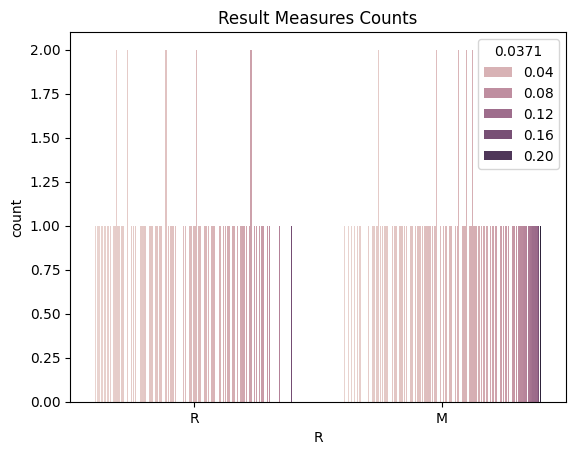

In [32]:
sns.countplot(x='R' , hue='0.0371',data=df)
plt.title('Result Measures Counts')
plt.show()

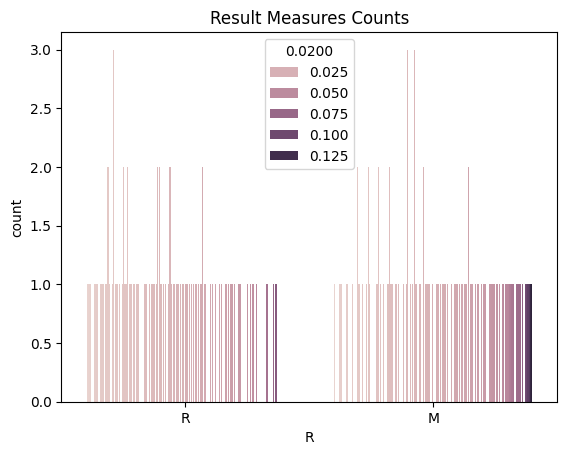

In [31]:
sns.countplot(x='R' , hue='0.0200',data=df)
plt.title('Result Measures Counts')
plt.show()

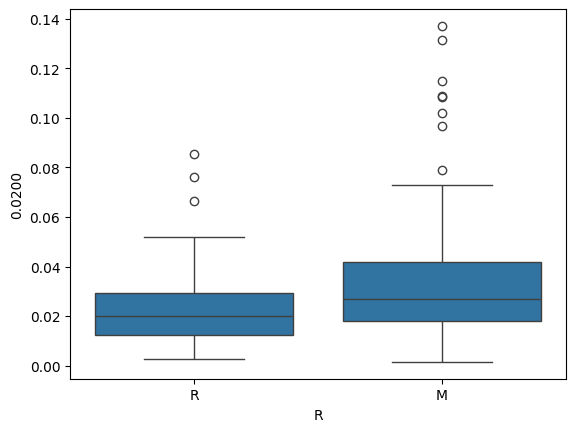

In [36]:
sns.boxplot(x=df['R'],y=df['0.0200'])
plt.show()

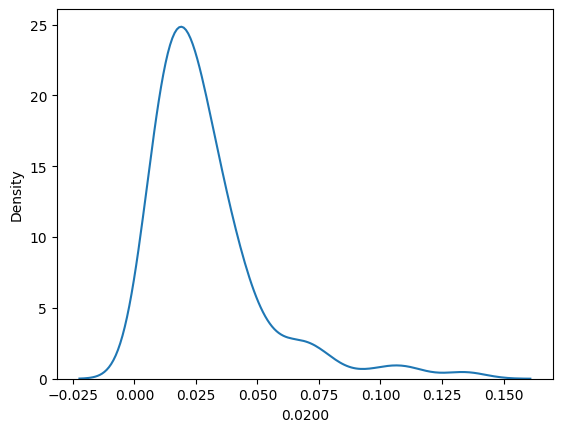

In [37]:
sns.kdeplot(df['0.0200'])
plt.show()

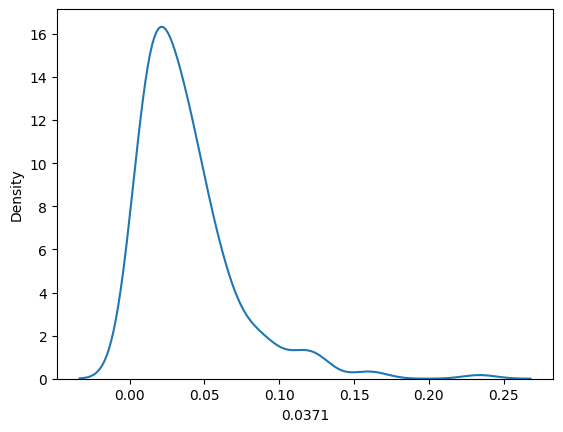

In [39]:
sns.kdeplot(df['0.0371'])
plt.show()

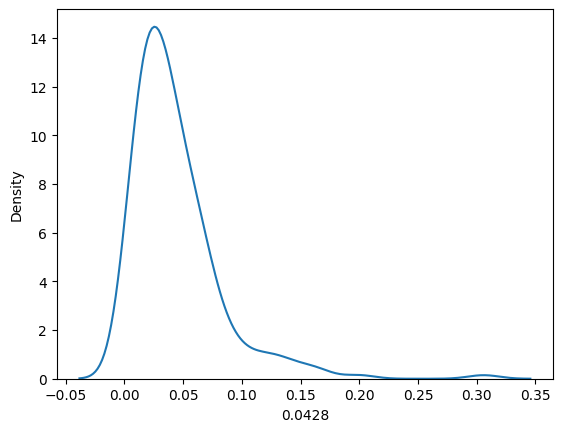

In [40]:
sns.kdeplot(df['0.0428'])
plt.show()

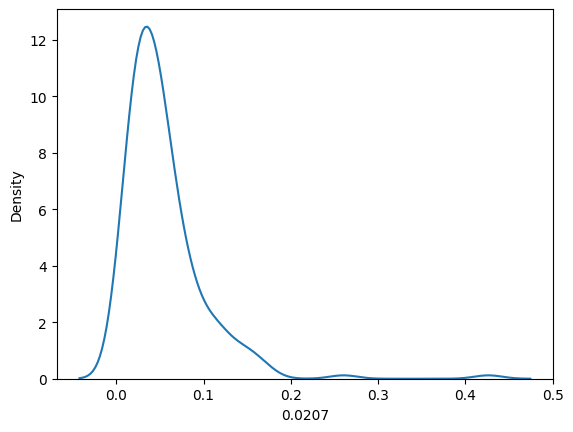

In [41]:
sns.kdeplot(df['0.0207'])
plt.show()

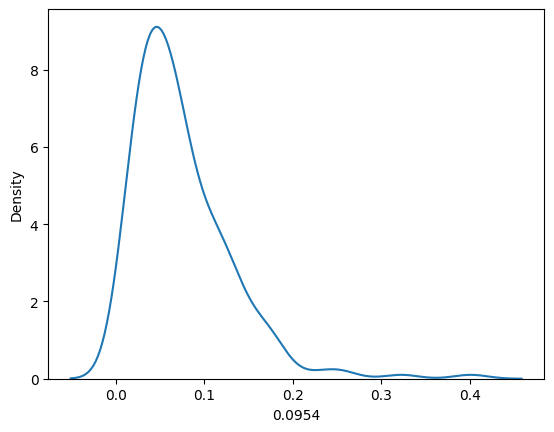

In [42]:
sns.kdeplot(df['0.0954'])
plt.show()

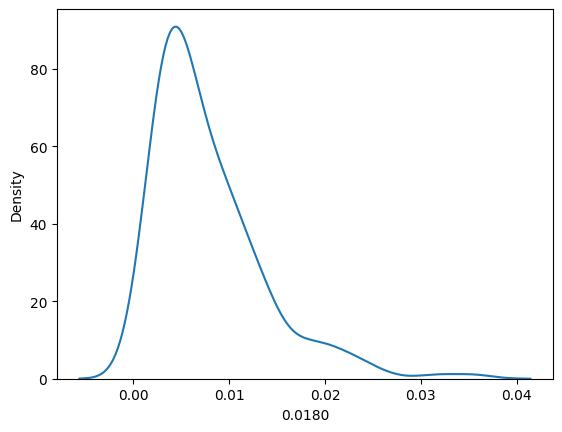

In [43]:
sns.kdeplot(df['0.0180'])
plt.show()

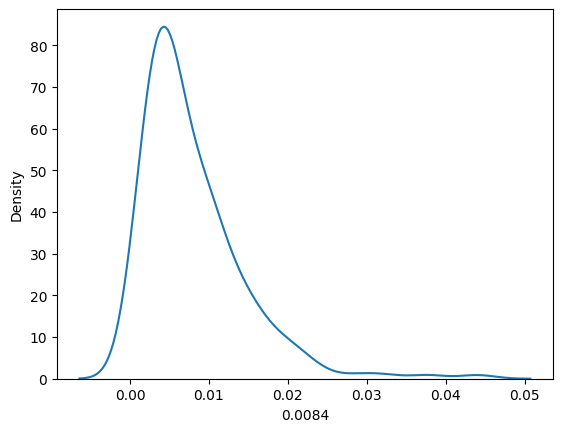

In [44]:
sns.kdeplot(df['0.0084'])
plt.show()

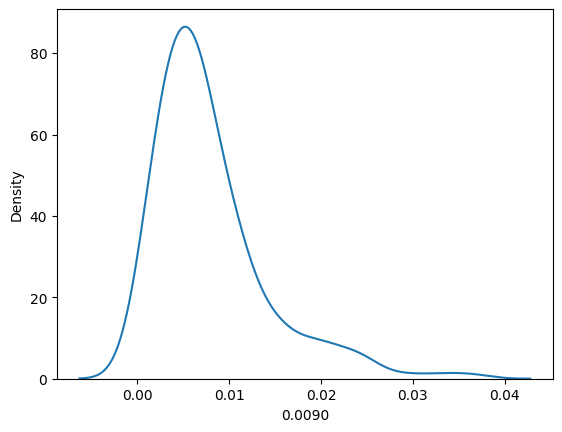

In [45]:
sns.kdeplot(df['0.0090'])
plt.show()

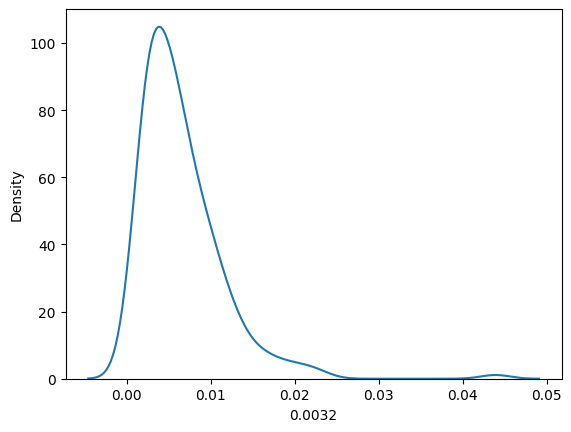

In [46]:
sns.kdeplot(df['0.0032'])
plt.show()

In [56]:
le = LabelEncoder()
df['R'] = le.fit_transform(df['R'])
df['R']

,R
0,1
1,1
2,1
3,1
4,1
...,...
202,0
203,0
204,0
205,0


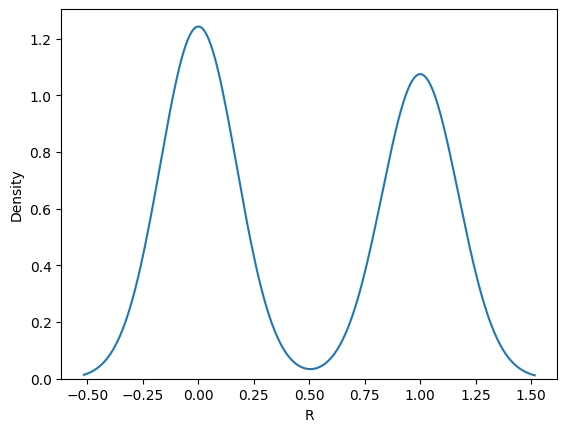

In [57]:
sns.kdeplot(df['R'])
plt.show()

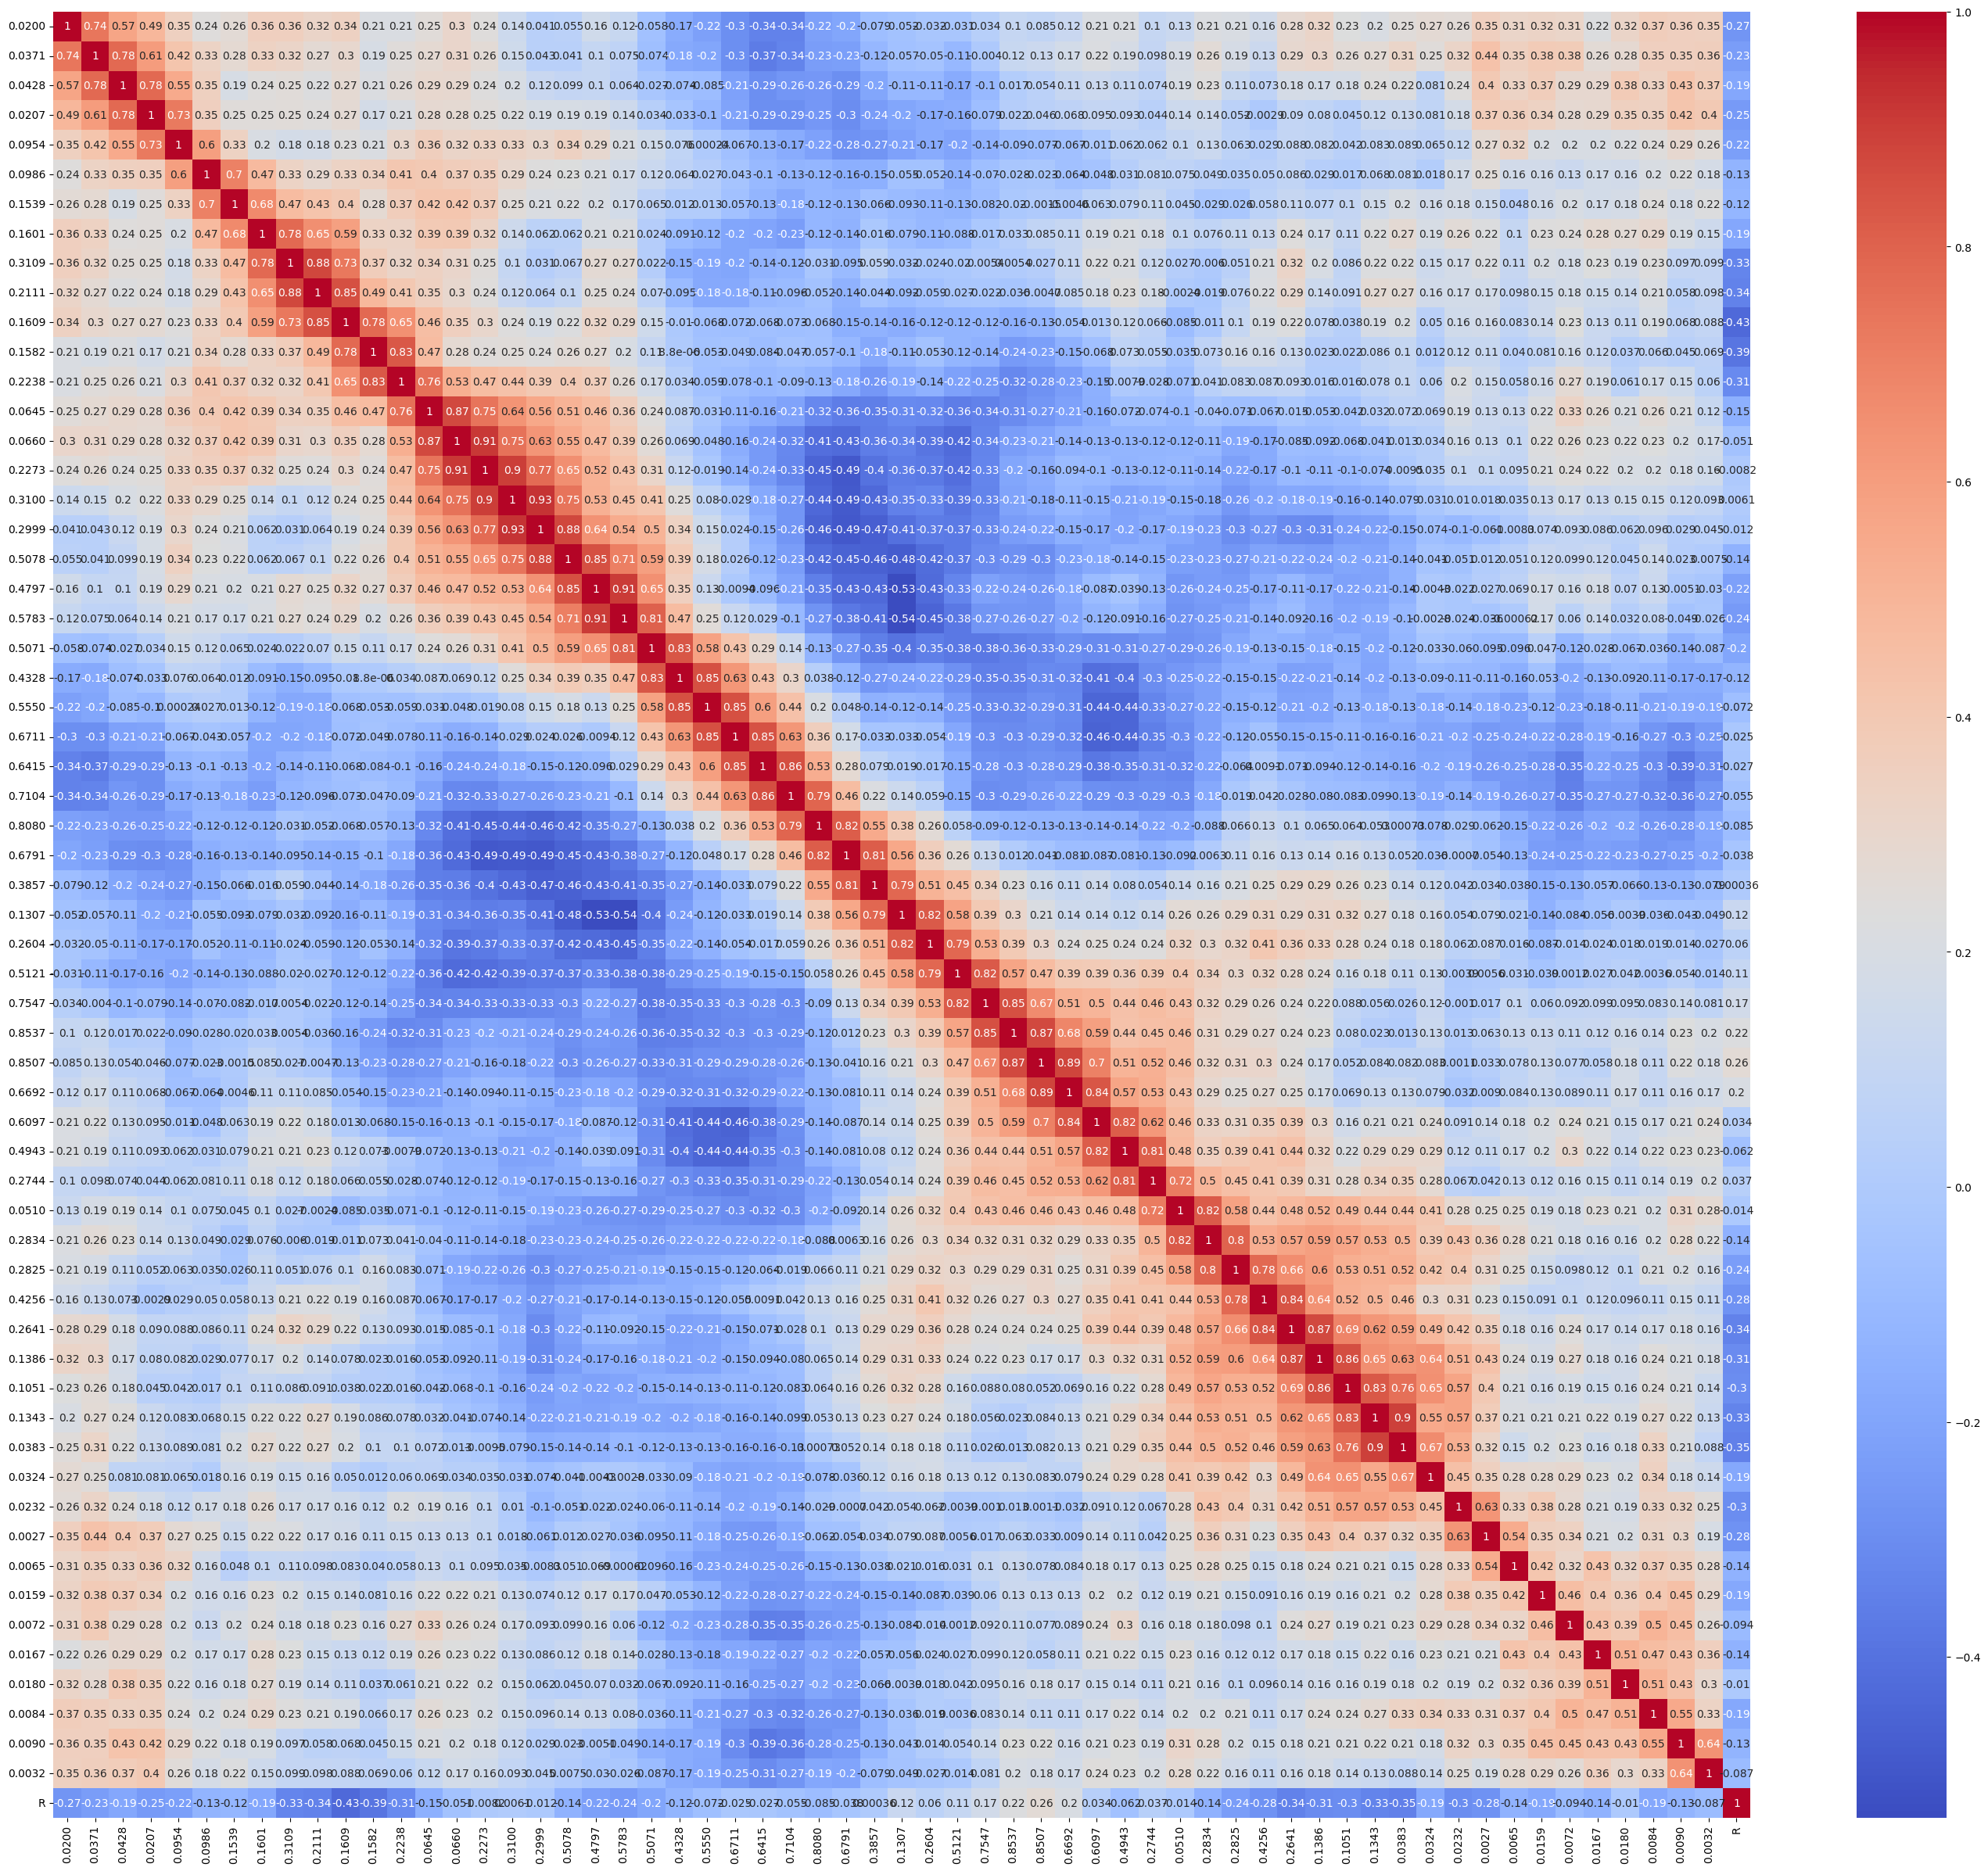

In [62]:
plt.figure(figsize=(35,30))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()